# 🧠 Curso de Python: Aula 16 - Introdução a Redes Neurais com PyTorch: Classificação Binária

**Bem-vindo à Aula 16!** Hoje daremos um salto fundamental na nossa jornada de programação em Python, adentrando o universo do **Aprendizado Profundo (*Deep Learning*)** com a biblioteca mais utilizada na pesquisa e na indústria moderna de Inteligência Artificial: o **PyTorch (`torch`)**.

Nesta aula prática e altamente didática, construiremos do zero um pipeline completo de classificação binária para distinguir duas espécies do clássico dataset de flores **Iris**.

---

### 🎯 Objetivos de Aprendizagem:
1. **Compreensão dos Dados e Features**: Carregar o dataset, selecionar as características (*features*) mais relevantes e visualizar as amostras (*pontos*) no espaço bidimensional.
2. **Anatomia da Rede Neural**: Entender as camadas lineares, as funções de ativação não-lineares ($\text{ReLU}$ e $\text{Sigmoid}$) e o fluxo de dados (*Forward Pass*).
3. **Mecanismo de Aprendizado**: Compreender a função de perda de **Entropia Cruzada Binária (*Binary Cross-Entropy Loss*)**, o otimizador **Adam** e o ciclo de retropropagação (*Backpropagation*).
4. **Curvas de Aprendizado**: Monitorar a evolução da perda (*Loss*) e da acurácia (*Accuracy*) ao longo das épocas de treino.
5. **Superfície e Fronteira de Decisão**: Visualizar no plano cartesiano como a rede neural "enxerga" o espaço e separa as duas espécies de flores.
6. **Figuras de Mérito**: Dominar com rigor matemático e intuição prática a **Matriz de Confusão**, **Acurácia (ACC)**, **Precisão**, **Sensibilidade / Revocação (Recall)**, **F1-Score** e **Especificidade**.
7. **Histogramas de Saída e Limiar de Decisão**: Visualizar as distribuições das probabilidades preditas pela rede nos conjuntos de treino e teste, o papel da linha de limiar (*threshold*) e as setas direcionais delimitando cada classe.
8. **Curva ROC e Métrica AUC**: Compreender como a variação do limiar governa a relação entre sensibilidade e falsos alarmes em todo o espectro operacional.


## 1. Configuração do Ambiente e Importação das Bibliotecas

Para esta aula, utilizaremos:
* **`torch` e `torch.nn`**: Para construir, instanciar e treinar nossa rede neural.
* **`torch.optim`**: Para o algoritmo de otimização (Adam).
* **`sklearn`**: Para carregar o dataset Iris, dividir conjuntos e calcular métricas de avaliação.
* **`matplotlib` e `seaborn`**: Para criar gráficos com acabamento visual de alto nível.
* **`numpy` e `pandas`**: Para manipulação matricial e estruturação de dados.


In [1]:
%matplotlib inline
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    roc_curve, 
    roc_auc_score, 
    classification_report
)

# Configuração de reprodutibilidade científica
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Estilização visual para gráficos limpos e didáticos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 11
plt.rcParams['figure.titlesize'] = 16

print(f" PyTorch instalado com sucesso! Versão: {torch.__version__}")
print(f" Dispositivo padrão: {'GPU (CUDA)' if torch.cuda.is_available() else 'CPU'}")


 PyTorch instalado com sucesso! Versão: 2.14.1
 Dispositivo padrão: CPU


## 2. O Dataset de Flores (Iris): Seleção de Features e Visualização dos Pontos

O dataset **Iris** contém medições morfológicas de flores pertencentes a 3 espécies.

Para realizarmos uma **classificação binária**, filtraremos o dataset para reter apenas duas espécies desafiadoras:
* **Classe 0: *Iris-versicolor***
* **Classe 1: *Iris-virginica***

*(Excluímos a Iris-setosa porque ela é trivialmente separável por uma reta simples).*

### 🌸 As Features Selecionadas:
Para permitir a visualização gráfica em um plano cartesiano 2D, escolheremos as duas características com maior poder discriminante:
1. **Comprimento da Pétala** (*Petal Length* em cm) $\implies$ Eixo $X$
2. **Largura da Pétala** (*Petal Width* em cm) $\implies$ Eixo $Y$


In [2]:
# 1. Carregamento do dataset original
iris = load_iris()

# 2. Filtragem binária: Selecionar apenas as classes 1 (Versicolor) e 2 (Virginica)
mascara_binaria = (iris.target != 0)
X_bruto = iris.data[mascara_binaria][:, [2, 3]]  # Apenas Colunas 2 (comp. pétala) e 3 (larg. pétala)
y_bruto = iris.target[mascara_binaria]

# 3. Re-rotulação para classificação binária padrão: {0, 1}
# Classe original 1 (Versicolor) -> 0
# Classe original 2 (Virginica)  -> 1
y_bruto = y_bruto - 1

nomes_classes = ['Versicolor (0)', 'Virginica (1)']
nomes_features = ['Comprimento da Pétala (cm)', 'Largura da Pétala (cm)']

# 4. Criação de um DataFrame do Pandas para visualização tabular
df_iris = pd.DataFrame(X_bruto, columns=nomes_features)
df_iris['Classe'] = y_bruto
df_iris['Espécie'] = df_iris['Classe'].map({0: 'Versicolor', 1: 'Virginica'})

print(f"Total de amostras selecionadas: {len(df_iris)} (50 de cada espécie)")
df_iris.head(8)


Total de amostras selecionadas: 100 (50 de cada espécie)


,Comprimento da Pétala (cm),Largura da Pétala (cm),Classe,Espécie
0,4.7,1.4,0,Versicolor
1,4.5,1.5,0,Versicolor
2,4.9,1.5,0,Versicolor
3,4.0,1.3,0,Versicolor
4,4.6,1.5,0,Versicolor
5,4.5,1.3,0,Versicolor
6,4.7,1.6,0,Versicolor
7,3.3,1.0,0,Versicolor


### 📍 Visualização dos Pontos no Espaço de Features (2D)

Ao plotar o **Comprimento da Pétala** no eixo $X$ e a **Largura da Pétala** no eixo $Y$, podemos observar a distribuição espacial de cada espécie.

Note que:
* As flores *Versicolor* (azul) concentram-se no canto inferior esquerdo (pétalas menores e mais finas).
* As flores *Virginica* (vermelho) concentram-se no canto superior direito (pétalas mais longas e mais grossas).
* Há uma **zona de transição e proximidade** entre 4,5 cm e 5,2 cm de comprimento, onde uma decisão puramente linear pode cometer equívocos.


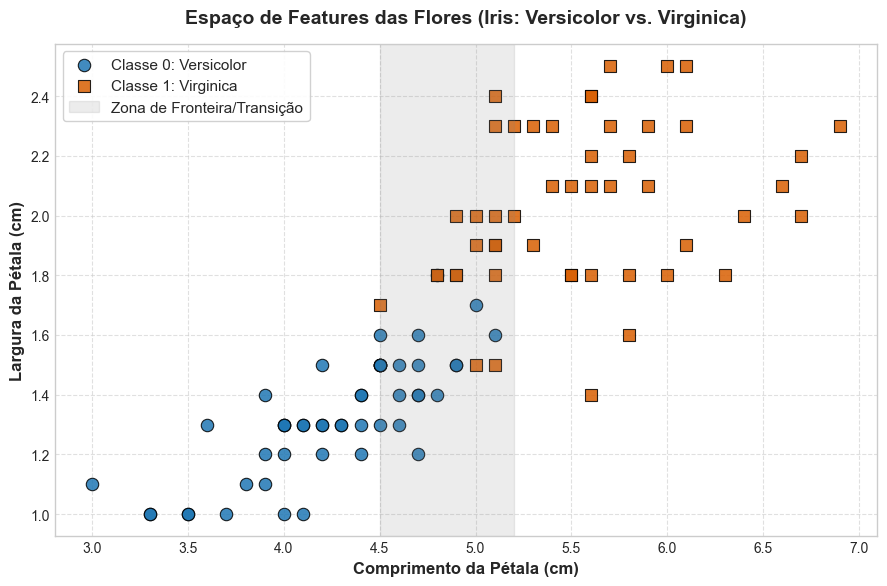

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))

# Cores didáticas de alto contraste
cores = {0: '#1f77b4', 1: '#d95f02'}
marcadores = {0: 'o', 1: 's'}

for classe_idx, nome_classe in enumerate(['Versicolor', 'Virginica']):
    sub = df_iris[df_iris['Classe'] == classe_idx]
    ax.scatter(
        sub['Comprimento da Pétala (cm)'], 
        sub['Largura da Pétala (cm)'],
        c=cores[classe_idx],
        marker=marcadores[classe_idx],
        s=80,
        alpha=0.85,
        edgecolor='black',
        linewidth=0.8,
        label=f'Classe {classe_idx}: {nome_classe}'
    )

ax.set_title("Espaço de Features das Flores (Iris: Versicolor vs. Virginica)", fontweight='bold', pad=15)
ax.set_xlabel("Comprimento da Pétala (cm)", fontweight='bold')
ax.set_ylabel("Largura da Pétala (cm)", fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')

# Destacar a região de fronteira natural
ax.axvspan(4.5, 5.2, color='gray', alpha=0.15, label='Zona de Fronteira/Transição')
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')

plt.tight_layout()
plt.show()


## 3. Divisão em Treino/Teste e Padronização das Features

Para avaliar o modelo de forma justa e evitar **vazamento de dados (*data leakage*)**, dividimos os dados em:
* **Conjunto de Treinamento (70%)**: Utilizado pela rede neural para aprender os pesos via gradiente descendente.
* **Conjunto de Teste (30%)**: Amostras nunca vistas durante o treinamento, reservadas exclusivamente para a avaliação final e cálculo das figuras de mérito.

### ⚖️ Por que normalizar as features com `StandardScaler`?
Redes Neurais utilizam multiplicações de matrizes e gradientes descendentes. Se as features estiverem em escalas muito distintas ou com médias distantes de zero:
1. O gradiente oscila desordenadamente, atrasando a convergência.
2. Neurônios podem saturar cedo demais.

A padronização subtrai a média $\mu$ e divide pelo desvio padrão $\sigma$:

$$z = \frac{x - \mu}{\sigma}$$

Garantindo que cada feature passe a ter média zero ($\mu = 0$) e variância unitária ($\sigma = 1$).


In [4]:
# 1. Divisão Estratificada (mantém 50% de cada classe em ambos os conjuntos)
X_train, X_test, y_train, y_test = train_test_split(
    X_bruto, y_bruto, 
    test_size=0.30, 
    random_state=SEED, 
    stratify=y_bruto
)

# 2. Padronização (ajustada SOMENTE no treino para evitar data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Conversão para Tensores do PyTorch (tipo float32)
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # Formato (N, 1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

print(f"📊 Dimensões dos Conjuntos:")
print(f" • X_train: {X_train_tensor.shape} | y_train: {y_train_tensor.shape} (70 amostras)")
print(f" • X_test:  {X_test_tensor.shape}  | y_test:  {y_test_tensor.shape}  (30 amostras)")


📊 Dimensões dos Conjuntos:
 • X_train: torch.Size([70, 2]) | y_train: torch.Size([70, 1]) (70 amostras)
 • X_test:  torch.Size([30, 2])  | y_test:  torch.Size([30, 1])  (30 amostras)


## 4. Estrutura da Rede Neural no PyTorch

Uma Rede Neural Artificial é composta por camadas de neurônios interconectados por pesos sinápticos e vieses (*biases*).

```
   [Entrada]                  [Camada Oculta]               [Camada de Saída]
(2 Features)                (16 Neurônios + ReLU)          (1 Neurônio + Sigmoid)

   x₁ (Comp. Pétala) ────┐     ┌─ [h₁] ─┐
                         ├───> ├─ [h₂] ─┤ ───> [Saída z] ──> [Sigmoid σ(z)] ──> Probabilidade p ∈ (0, 1)
   x₂ (Larg. Pétala) ────┘     └─ [h₁₆] ┘
```

### 🧩 Elementos da nossa arquitetura:
1. **Camada de Entrada**: Recebe 2 valores numéricos ($x_1$: Comprimento da Pétala normalizado, $x_2$: Largura da Pétala normalizada).
2. **Camada Linear Oculta (`nn.Linear(2, 16)`)**:
   Calcula 16 combinações lineares:

$$\mathbf{z}_1 = \mathbf{X} \mathbf{W}_1 + \mathbf{b}_1$$

   * Matriz de Pesos $\mathbf{W}_1$: tamanho $(2, 16) \implies 32$ pesos.
   * Vetor de Viés $\mathbf{b}_1$: tamanho $(16) \implies 16$ vieses.

3. **Função de Ativação Não-Linear (`nn.ReLU`)**:

$$\text{ReLU}(z) = \max(0, z)$$

   * Se o valor for negativo, torna-se $0$; se positivo, mantém o valor.
   * **Por que é crucial?** Sem ativações não-lineares, a rede seria apenas uma regressão linear disfarçada, incapaz de curvar ou moldar superfícies de decisão complexas.

4. **Camada Linear de Saída (`nn.Linear(16, 1)`)**:
   Combina os 16 neurônios ocultos em um único valor escalar $z_{\text{out}}$:
   * Matriz de Pesos $\mathbf{W}_2$: tamanho $(16, 1) \implies 16$ pesos.
   * Viés $\mathbf{b}_2$: tamanho $(1) \implies 1$ viés.

5. **Função de Ativação Sigmoide (`nn.Sigmoid`)**:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

   * Mapeia qualquer número real de $(-\infty, +\infty)$ estritamente para o intervalo $(0, 1)$.
   * Esse valor é interpretado diretamente como a **probabilidade** da amostra pertencer à **Classe 1 (Virginica)**:

$$p = P(y = 1 \mid \mathbf{x})$$

**Total de parâmetros treináveis da rede:**

$$\text{Total} = (2 \times 16 + 16) + (16 \times 1 + 1) = 48 + 17 = 65$$

São exatamente **65 parâmetros livres** ajustados durante o aprendizado.


In [5]:
class RedeClassificacaoFlores(nn.Module):
    """
    Rede Neural Perceptron Multicamadas (MLP) para Classificação Binária.
    Arquitetura: 2 -> 16 (ReLU) -> 1 (Sigmoid)
    """
    def __init__(self, n_features_entrada=2, n_neuronios_ocultos=16):
        super(RedeClassificacaoFlores, self).__init__()
        
        # Camada densa 1: mapeia 2 features de entrada para 16 neurônios ocultos
        self.camada_oculta = nn.Linear(n_features_entrada, n_neuronios_ocultos)
        
        # Ativação não-linear ReLU
        self.ativacao_relu = nn.ReLU()
        
        # Camada densa 2: mapeia 16 neurônios para 1 neurônio de saída
        self.camada_saida = nn.Linear(n_neuronios_ocultos, 1)
        
        # Função Sigmoide para restringir a saída a [0, 1] (Probabilidade)
        self.ativacao_sigmoid = nn.Sigmoid()

    def forward(self, x):
        # Propagação para frente (Forward Pass)
        z1 = self.camada_oculta(x)
        h1 = self.ativacao_relu(z1)
        z2 = self.camada_saida(h1)
        probabilidade = self.ativacao_sigmoid(z2)
        return probabilidade

# Instanciação da Rede
modelo = RedeClassificacaoFlores(n_features_entrada=2, n_neuronios_ocultos=16)
print("🏗️ Estrutura Arquitetural da Rede:")
print(modelo)

# Contagem detalhada dos parâmetros treináveis
print("\n🔍 Detalhamento dos Parâmetros Treináveis:")
total_params = 0
for nome, param in modelo.named_parameters():
    print(f" • {nome:30s}: shape {str(list(param.shape)):12s} | {param.numel():3d} parâmetros")
    total_params += param.numel()
print(f"-------------------------------------------------------------")
print(f" Total de Parâmetros Livres: {total_params}")


🏗️ Estrutura Arquitetural da Rede:
RedeClassificacaoFlores(
  (camada_oculta): Linear(in_features=2, out_features=16, bias=True)
  (ativacao_relu): ReLU()
  (camada_saida): Linear(in_features=16, out_features=1, bias=True)
  (ativacao_sigmoid): Sigmoid()
)

🔍 Detalhamento dos Parâmetros Treináveis:
 • camada_oculta.weight          : shape [16, 2]      |  32 parâmetros
 • camada_oculta.bias            : shape [16]         |  16 parâmetros
 • camada_saida.weight           : shape [1, 16]      |  16 parâmetros
 • camada_saida.bias             : shape [1]          |   1 parâmetros
-------------------------------------------------------------
 Total de Parâmetros Livres: 65


## 5. Função de Perda (Loss) e Otimizador

Para a rede aprender, precisamos de duas peças fundamentais:

### 📉 1. A Função de Custo: Entropia Cruzada Binária (`BCELoss`)
A Entropia Cruzada Binária mede quão "surpreso" ou distante o modelo está da verdade:

$$\mathcal{L}(\mathbf{y}, \hat{\mathbf{y}}) = -\frac{1}{N} \sum_{i=1}^N \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

* **Se a flor for Virginica ($y = 1$)**: A perda simplifica para $-\log(\hat{y})$.
  * Se a rede prever $\hat{y} = 0.99 \implies -\log(0.99) \approx 0.01$ (perda minúscula, quase perfeita).
  * Se a rede prever $\hat{y} = 0.01 \implies -\log(0.01) \approx 4.60$ (penalidade gigantesca!).
* **Se a flor for Versicolor ($y = 0$)**: A perda simplifica para $-\log(1 - \hat{y})$.

### 🚀 2. O Otimizador: Adam (`optim.Adam`)
O **Adam (*Adaptive Moment Estimation*)** ajusta automaticamente a taxa de aprendizado para cada peso sináptico com base na média móvel dos gradientes e dos seus quadrados, proporcionando convergência rápida e estável.

### 🔄 As 5 Etapas do Treinamento no PyTorch:
A cada época (*epoch*), executamos religiosamente o ciclo fundamental:
1. `optimizer.zero_grad()`: Zera os gradientes acumulados da iteração anterior.
2. `pred = modelo(X)`: Realiza o *Forward Pass* (gera as predições).
3. `loss = criterion(pred, y)`: Calcula o erro da época.
4. `loss.backward()`: Executa o *Backpropagation* (calcula as derivadas parciais $\frac{\partial \mathcal{L}}{\partial W}$).
5. `optimizer.step()`: Atualiza todos os pesos na direção que reduz a perda.


In [6]:
# Função de Perda para problemas binários com saída Sigmoide
criterion = nn.BCELoss()

# Otimizador com taxa de aprendizado (Learning Rate) definida para 0.03
LEARNING_RATE = 0.03
optimizer = optim.Adam(modelo.parameters(), lr=LEARNING_RATE)

print(f"🎯 Critério de Perda : {criterion}")
print(f"⚙️ Otimizador        : {optimizer.__class__.__name__} (lr={LEARNING_RATE})")


🎯 Critério de Perda : BCELoss()
⚙️ Otimizador        : Adam (lr=0.03)


## 6. Treinamento da Rede e Curvas de Aprendizado (Loss e Acurácia)

Agora executaremos o loop de treino por **120 épocas**, registrando a cada iteração tanto a perda quanto a acurácia no treino e no teste.


In [7]:
NUM_EPOCAS = 120

historico_perda_treino = []
historico_perda_teste = []
historico_acc_treino = []
historico_acc_teste = []

print("🚀 Iniciando o Treinamento da Rede Neural...")
print(f"{'Época':^7} | {'Loss Treino':^12} | {'Loss Teste':^12} | {'ACC Treino':^11} | {'ACC Teste':^11}")
print("-" * 62)

for epoca in range(1, NUM_EPOCAS + 1):
    # ========================== MODO TREINO ==========================
    modelo.train()
    
    # 1. Zera gradientes
    optimizer.zero_grad()
    
    # 2. Forward pass (Treino)
    y_pred_treino_prob = modelo(X_train_tensor)
    loss_treino = criterion(y_pred_treino_prob, y_train_tensor)
    
    # 3. Backward pass (cálculo dos gradientes)
    loss_treino.backward()
    
    # 4. Atualização dos parâmetros da rede
    optimizer.step()
    
    # Cálculo da acurácia de treino (limiar 0.5)
    y_pred_treino_rotulo = (y_pred_treino_prob >= 0.5).float()
    acc_treino = (y_pred_treino_rotulo == y_train_tensor).float().mean().item()
    
    # ========================== MODO AVALIAÇÃO ==========================
    modelo.eval()
    with torch.no_grad():
        y_pred_teste_prob = modelo(X_test_tensor)
        loss_teste = criterion(y_pred_teste_prob, y_test_tensor)
        y_pred_teste_rotulo = (y_pred_teste_prob >= 0.5).float()
        acc_teste = (y_pred_teste_rotulo == y_test_tensor).float().mean().item()
        
    # Registro das métricas
    historico_perda_treino.append(loss_treino.item())
    historico_perda_teste.append(loss_teste.item())
    historico_acc_treino.append(acc_treino)
    historico_acc_teste.append(acc_teste)
    
    # Exibição periódica
    if epoca == 1 or epoca % 20 == 0 or epoca == NUM_EPOCAS:
        print(f"{epoca:^7d} | {loss_treino.item():^12.4f} | {loss_teste.item():^12.4f} | {acc_treino*100:^10.1f}% | {acc_teste*100:^10.1f}%")

print("-" * 62)
print("✅ Treinamento finalizado com sucesso!")


🚀 Iniciando o Treinamento da Rede Neural...
 Época  | Loss Treino  |  Loss Teste  | ACC Treino  |  ACC Teste 
--------------------------------------------------------------
   1    |    0.6618    |    0.5946    |    50.0   % |    80.0   %
  20    |    0.0728    |    0.1967    |    95.7   % |    90.0   %
  40    |    0.0665    |    0.2452    |    95.7   % |    90.0   %
  60    |    0.0661    |    0.2380    |    95.7   % |    90.0   %
  80    |    0.0651    |    0.2261    |    95.7   % |    90.0   %
  100   |    0.0644    |    0.2194    |    95.7   % |    90.0   %
  120   |    0.0637    |    0.2171    |    95.7   % |    90.0   %
--------------------------------------------------------------
✅ Treinamento finalizado com sucesso!


### 📈 Visualização das Curvas de Treino (Loss e Accuracy)

As curvas de aprendizado nos mostram a dinâmica da descida do gradiente:
* **Curva da Perda (*Loss*)**: O erro decresce monótona e consistentemente, convergindo para patamares muito baixos.
* **Curva da Acurácia (*Accuracy*)**: Ambas as acurácias (treino e teste) sobem rapidamente e estabilizam acima de 90%, evidenciando ausência de *overfitting* grave.


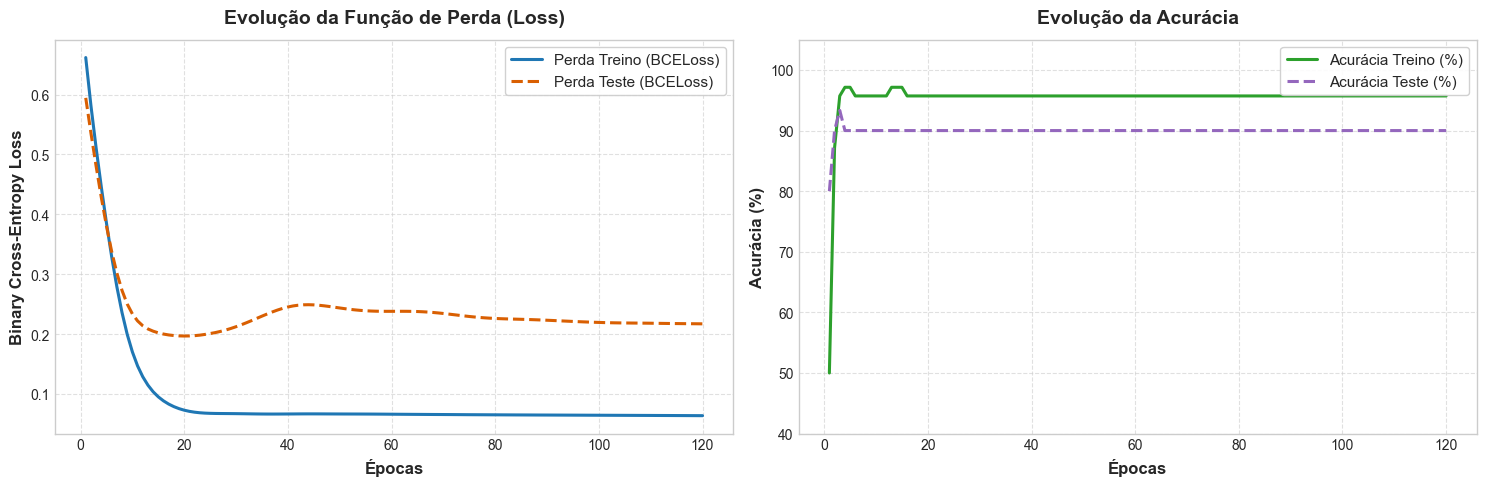

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

epocas = range(1, NUM_EPOCAS + 1)

# Gráfico 1: Curva da Função de Custo (Loss)
axes[0].plot(epocas, historico_perda_treino, label='Perda Treino (BCELoss)', color='#1f77b4', linewidth=2.2)
axes[0].plot(epocas, historico_perda_teste, label='Perda Teste (BCELoss)', color='#d95f02', linewidth=2.2, linestyle='--')
axes[0].set_title("Evolução da Função de Perda (Loss)", fontweight='bold', pad=12)
axes[0].set_xlabel("Épocas", fontweight='bold')
axes[0].set_ylabel("Binary Cross-Entropy Loss", fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Gráfico 2: Curva da Acurácia
axes[1].plot(epocas, [a * 100 for a in historico_acc_treino], label='Acurácia Treino (%)', color='#2ca02c', linewidth=2.2)
axes[1].plot(epocas, [a * 100 for a in historico_acc_teste], label='Acurácia Teste (%)', color='#9467bd', linewidth=2.2, linestyle='--')
axes[1].set_title("Evolução da Acurácia", fontweight='bold', pad=12)
axes[1].set_xlabel("Épocas", fontweight='bold')
axes[1].set_ylabel("Acurácia (%)", fontweight='bold')
axes[1].set_ylim(40, 105)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()


## 7. Resultados de Classificação: A Fronteira de Decisão no Espaço 2D

Como a rede neural enxerga todo o espaço de flores possíveis?

Podemos criar uma grade densa de pontos no plano 2D, passá-la pela rede neural e plotar a **superfície contínua de probabilidades**:
* Região Azul: Probabilidade $P(y = 1 \mid \mathbf{x}) < 0.5$ (Predição: *Versicolor*)
* Região Vermelha: Probabilidade $P(y = 1 \mid \mathbf{x}) \ge 0.5$ (Predição: *Virginica*)
* **Linha Branca / Tracejada**: A Fronteira Exata de Decisão onde $P(y = 1 \mid \mathbf{x}) = 0.50$!


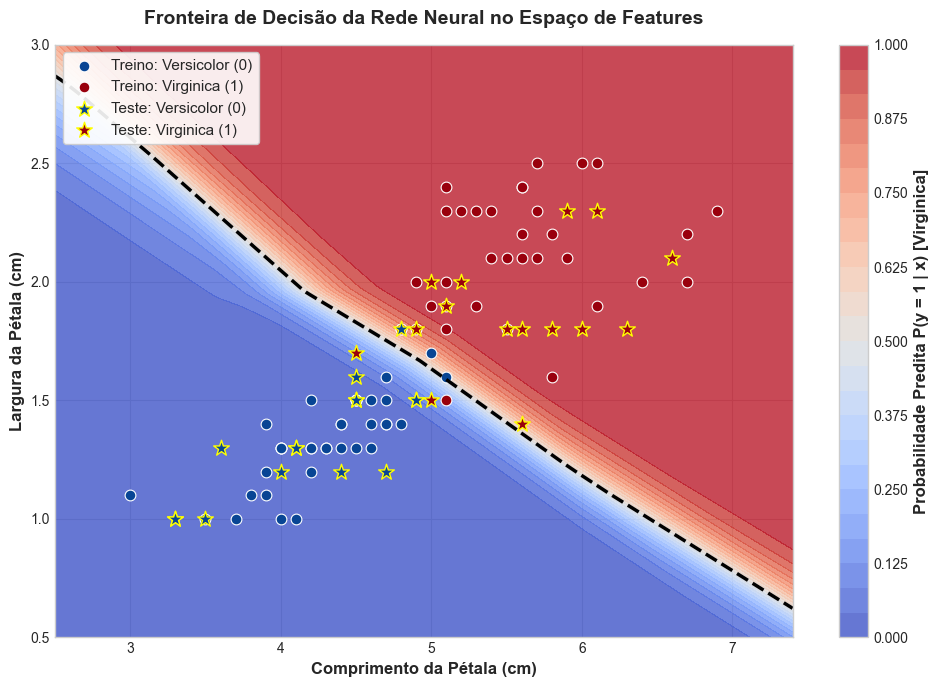

In [9]:
# 1. Definir limites da grade no espaço original (em centímetros)
x_min, x_max = X_bruto[:, 0].min() - 0.5, X_bruto[:, 0].max() + 0.5
y_min, y_max = X_bruto[:, 1].min() - 0.5, X_bruto[:, 1].max() + 0.5

# 2. Criar malha fina de amostragem
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid_original = np.c_[xx.ravel(), yy.ravel()]

# 3. Normalizar a malha com o mesmo StandardScaler do treino
grid_scaled = scaler.transform(grid_original)
grid_tensor = torch.tensor(grid_scaled, dtype=torch.float32)

# 4. Inferência contínua com a rede neural treinada
modelo.eval()
with torch.no_grad():
    probs_grid = modelo(grid_tensor).numpy().reshape(xx.shape)

# 5. Visualização gráfica de alto nível
fig, ax = plt.subplots(figsize=(10, 7))

# Mapa contínuo de probabilidades (contourf)
contorno = ax.contourf(
    xx, yy, probs_grid, 
    levels=np.linspace(0, 1, 25), 
    cmap='coolwarm', 
    alpha=0.80
)
cbar = plt.colorbar(contorno, ax=ax)
cbar.set_label('Probabilidade Predita P(y = 1 | x) [Virginica]', fontweight='bold')

# Linha da fronteira de decisão (P = 0.50)
ax.contour(
    xx, yy, probs_grid, 
    levels=[0.5], 
    colors='black', 
    linewidths=2.5, 
    linestyles='--'
)

# Plotagem dos pontos de Treino e Teste
cores_pontos = {0: '#084594', 1: '#99000d'}

# Amostras de Treinamento (círculos)
for c in [0, 1]:
    idx = (y_train == c)
    ax.scatter(
        X_train[idx, 0], X_train[idx, 1],
        c=cores_pontos[c], marker='o', s=60, edgecolors='white', linewidth=0.8,
        label=f'Treino: {nomes_classes[c]}'
    )

# Amostras de Teste (estrelas em destaque)
for c in [0, 1]:
    idx = (y_test == c)
    ax.scatter(
        X_test[idx, 0], X_test[idx, 1],
        c=cores_pontos[c], marker='*', s=140, edgecolors='yellow', linewidth=1.0,
        label=f'Teste: {nomes_classes[c]}'
    )

ax.set_title("Fronteira de Decisão da Rede Neural no Espaço de Features", fontweight='bold', pad=15)
ax.set_xlabel("Comprimento da Pétala (cm)", fontweight='bold')
ax.set_ylabel("Largura da Pétala (cm)", fontweight='bold')
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')

plt.tight_layout()
plt.show()


## 8. Figuras de Mérito: Avaliação Rigorosa de Classificação

Para avaliar o desempenho de um classificador binário, nunca devemos nos limitar a olhar um único número isolado. É fundamental dissecar o comportamento do modelo através das principais **figuras de mérito da literatura**.

---

### 🔲 1. A Matriz de Confusão
A matriz de confusão cruza os valores reais do mundo físico contra as predições geradas pelo modelo:

| | **Predito: Negativo (Versicolor)** | **Predito: Positivo (Virginica)** |
|---|:---:|:---:|
| **Real: Negativo (Versicolor)** | **Verdadeiro Negativo ($TN$)** | **Falso Positivo ($FP$)** *(Erro Tipo I)* |
| **Real: Positivo (Virginica)** | **Falso Negativo ($FN$)** *(Erro Tipo II)* | **Verdadeiro Positivo ($TP$)** |

* **$TN$ (True Negative)**: A flor era *Versicolor* e a rede classificou corretamente como *Versicolor*.
* **$TP$ (True Positive)**: A flor era *Virginica* e a rede classificou corretamente como *Virginica*.
* **$FP$ (False Positive)**: A flor era *Versicolor*, mas a rede acusou erroneamente *Virginica* (*alarme falso*).
* **$FN$ (False Negative)**: A flor era *Virginica*, mas a rede deixou escapar como *Versicolor* (*omissão*).

---

### 📐 2. Definições Matemáticas das Métricas Fundamentais

#### A. Acurácia (ACC):

$$\text{ACC} = \frac{TP + TN}{TP + TN + FP + FN}$$

* **O que mede?** A proporção total de predições corretas em relação ao todo.
* **Cuidado**: Em datasets desbalanceados (ex.: detecção de fraudes com 99% de transações legítimas), a acurácia é traiçoeira. Em datasets balanceados como o nosso, é uma métrica muito informativa.

#### B. Precisão (Precision / Valor Preditivo Positivo):

$$\text{Precision} = \frac{TP}{TP + FP}$$

* **Pergunta que responde**: *"De todas as flores que o modelo jurou serem Virginica, quantas realmente eram?"*
* Mede o custo do alarme falso ($FP$).

#### C. Sensibilidade / Revocação (Recall / Sensitivity / TPR):

$$\text{Recall} = \frac{TP}{TP + FN}$$

* **Pergunta que responde**: *"De todas as flores Virginica que existiam no jardim, quantas o modelo conseguiu capturar?"*
* Mede o custo da omissão ($FN$).

#### D. F1-Score:

$$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

* Média harmônica entre Precisão e Revocação. Se qualquer uma das duas for muito baixa, o F1 despenca, penalizando modelos desequilibrados.

#### E. Especificidade (Specificity / TNR):

$$\text{Specificity} = \frac{TN}{TN + FP}$$

* A capacidade de classificar corretamente os casos negativos reais.


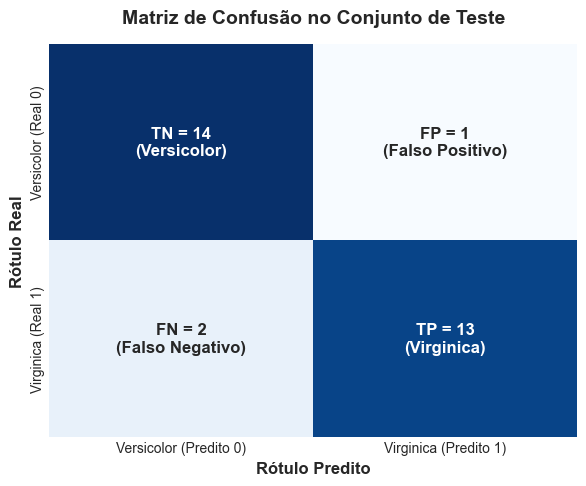

📋 Tabela Consolidada de Figuras de Mérito:


,Métrica,Fórmula,Valor Numérico,Percentual
0,Acurácia (ACC),(TP + TN) / Total,0.9000,90.00%
1,Precisão (Precision),TP / (TP + FP),0.9286,92.86%
2,Sensibilidade (Recall),TP / (TP + FN),0.8667,86.67%
3,F1-Score,2 * (P * R) / (P + R),0.8966,89.66%
4,Especificidade (TNR),TN / (TN + FP),0.9333,93.33%


In [10]:
# 1. Obtenção das predições do conjunto de teste
modelo.eval()
with torch.no_grad():
    y_test_probs = modelo(X_test_tensor).numpy().ravel()

# Limiar de corte padrão: tau = 0.50
y_test_pred = (y_test_probs >= 0.5).astype(int)

# 2. Cálculo da Matriz de Confusão
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

# 3. Visualização Gráfica da Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 5))

rotulos_matriz = [
    [f"TN = {tn}\n(Versicolor)", f"FP = {fp}\n(Falso Positivo)"],
    [f"FN = {fn}\n(Falso Negativo)", f"TP = {tp}\n(Virginica)"]
]

sns.heatmap(
    cm, annot=rotulos_matriz, fmt="", cmap="Blues", cbar=False,
    xticklabels=['Versicolor (Predito 0)', 'Virginica (Predito 1)'],
    yticklabels=['Versicolor (Real 0)', 'Virginica (Real 1)'],
    annot_kws={"size": 12, "fontweight": "bold"}, ax=ax
)

ax.set_title("Matriz de Confusão no Conjunto de Teste", fontweight='bold', pad=15)
ax.set_ylabel("Rótulo Real", fontweight='bold')
ax.set_xlabel("Rótulo Predito", fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Cálculo das Métricas Escalares
acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
especificidade = tn / (tn + fp)

tabela_metricas = pd.DataFrame({
    'Métrica': ['Acurácia (ACC)', 'Precisão (Precision)', 'Sensibilidade (Recall)', 'F1-Score', 'Especificidade (TNR)'],
    'Fórmula': ['(TP + TN) / Total', 'TP / (TP + FP)', 'TP / (TP + FN)', '2 * (P * R) / (P + R)', 'TN / (TN + FP)'],
    'Valor Numérico': [f"{acc:.4f}", f"{prec:.4f}", f"{rec:.4f}", f"{f1:.4f}", f"{especificidade:.4f}"],
    'Percentual': [f"{acc*100:.2f}%", f"{prec*100:.2f}%", f"{rec*100:.2f}%", f"{f1*100:.2f}%", f"{especificidade*100:.2f}%"]
})

print("📋 Tabela Consolidada de Figuras de Mérito:")
display(tabela_metricas)


## 9. Distribuição das Saídas da Rede: Histograma de Probabilidades (Treino e Teste)

Antes de investigarmos a Curva ROC, precisamos compreender a **natureza contínua** da saída da nossa rede neural.

A última camada do nosso modelo é uma função **Sigmoide** ($\text{Sigmoid}$), que mapeia a combinação linear final em um valor real contínuo no intervalo $[0, 1]$:

$$p = P(y = 1 \mid \mathbf{x}) \in [0, 1]$$

Esse valor $p$ representa a estimativa da rede de que a flor pertença à espécie **Virginica (Classe 1)**.

---

### 🎚️ O Papel do Limiar de Decisão (*Decision Threshold* $\tau = 0.50$)

Para converter uma probabilidade contínua em uma decisão categórica definitiva, estabelecemos uma linha divisória vertical em $\tau = 0.50$:

* **À Esquerda ($\leftarrow$) do Limiar ($p < 0.50$)**:
  * O modelo decide: **Classe 0 (Iris-versicolor)**.
  * Todas as amostras que caírem à esquerda da linha tracejada são classificadas como Versicolor.
* **À Direita ($\rightarrow$) do Limiar ($p \ge 0.50$)**:
  * O modelo decide: **Classe 1 (Iris-virginica)**.
  * Todas as amostras que caírem à direita da linha tracejada são classificadas como Virginica.

---

### 🔍 Conexão Direta com os Erros da Matriz de Confusão

Ao inspecionar a sobreposição das barras nos histogramas abaixo, podemos ver com clareza a origem dos acertos e erros:
1. **Verdadeiros Negativos ($TN$)**: Amostras reais de *Versicolor* (azul) que caem à **esquerda** de $0.50$ (classificadas corretamente como 0).
2. **Verdadeiros Positivos ($TP$)**: Amostras reais de *Virginica* (laranja) que caem à **direita** de $0.50$ (classificadas corretamente como 1).
3. **Falsos Positivos ($FP$)**: Qualquer amostra real de *Versicolor* (azul) que transborde para a **direita** do limiar ($p \ge 0.50$). O modelo disparou um alarme falso!
4. **Falsos Negativos ($FN$)**: Qualquer amostra real de *Virginica* (laranja) que caia para a **esquerda** do limiar ($p < 0.50$). O modelo a omitiu erradamente como Versicolor!

### ⚖️ Comparação entre Treino e Teste:
* No **Conjunto de Treinamento**: A rede foi otimizada para afastar as classes, empurrando as probabilidades das amostras para próximo de $0$ ou $1$.
* No **Conjunto de Teste**: Avaliamos a real capacidade de generalização da rede em dados inéditos, verificando se as classes continuam bem separadas pelo limiar.


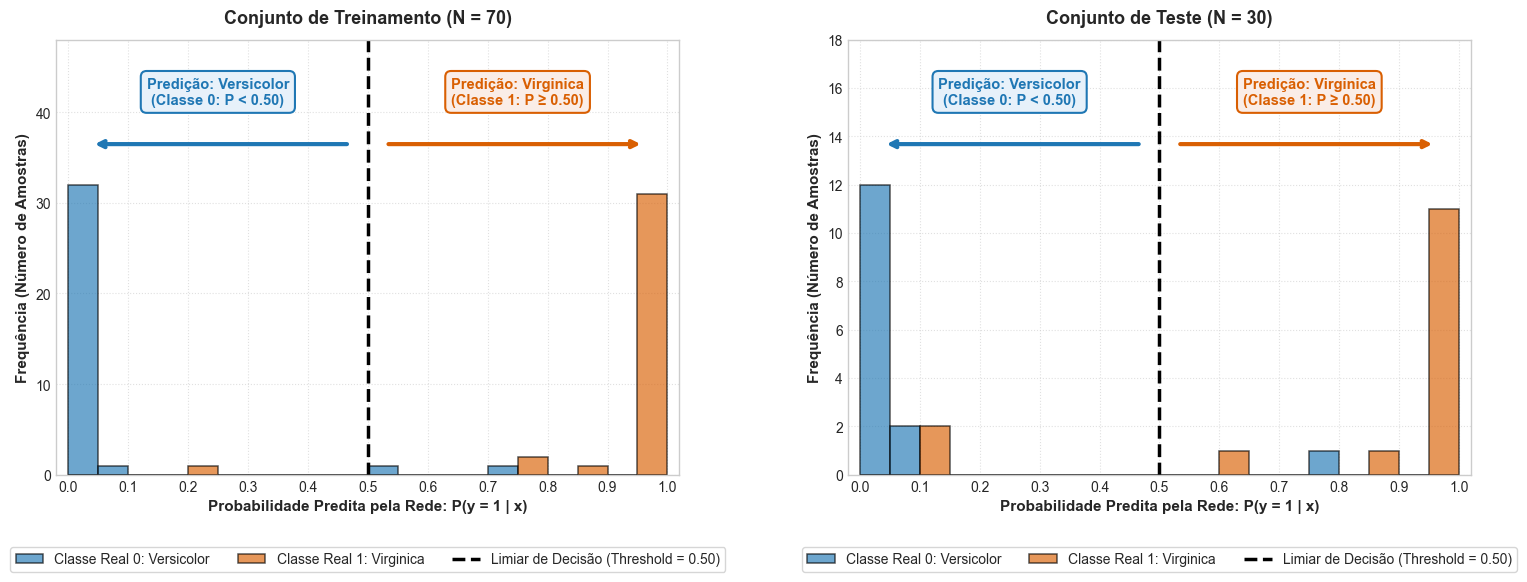

📊 Análise Detalhada dos Histogramas em Relação ao Limiar (tau = 0.50):
 • Treino (N=70): FP (Versicolor com P >= 0.5) = 2 | FN (Virginica com P < 0.5) = 1
 • Teste  (N=30): FP (Versicolor com P >= 0.5) = 1 | FN (Virginica com P < 0.5) = 2


In [11]:
# 1. Obtenção das probabilidades contínuas para ambos os conjuntos (Treino e Teste)
modelo.eval()
with torch.no_grad():
    y_train_probs = modelo(X_train_tensor).numpy().ravel()
    y_test_probs = modelo(X_test_tensor).numpy().ravel()

# 2. Configuração dos subplots (Treino vs Teste lado a lado)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

datasets_info = [
    ("Conjunto de Treinamento (N = 70)", y_train, y_train_probs, axes[0]),
    ("Conjunto de Teste (N = 30)", y_test, y_test_probs, axes[1])
]

# 20 intervalos entre 0.0 e 1.0 (largura de 0.05 por bin)
bins = np.linspace(0.0, 1.0, 21)

for title, y_true, y_probs, ax in datasets_info:
    # Histograma para a Classe Real 0 (Versicolor) em azul
    n0, _, _ = ax.hist(
        y_probs[y_true == 0], bins=bins, color="#1f77b4", alpha=0.65,
        edgecolor="black", linewidth=1.1, label="Classe Real 0: Versicolor"
    )
    # Histograma para a Classe Real 1 (Virginica) em laranja
    n1, _, _ = ax.hist(
        y_probs[y_true == 1], bins=bins, color="#d95f02", alpha=0.65,
        edgecolor="black", linewidth=1.1, label="Classe Real 1: Virginica"
    )
    
    # Linha vertical destacando o limiar de decisão (Threshold = 0.50)
    ax.axvline(
        0.5, color="black", linestyle="--", linewidth=2.5,
        label="Limiar de Decisão (Threshold = 0.50)"
    )
    
    # Ajuste de limite do eixo Y para acomodar as setas e caixas explicativas
    max_h = max(n0.max(), n1.max())
    ax.set_ylim(0, max_h * 1.50)
    y_box = max_h * 1.32
    y_arrow = max_h * 1.14
    
    # Caixa explicativa da região à esquerda (Classe 0)
    ax.text(
        0.25, y_box, "Predição: Versicolor\n(Classe 0: P < 0.50)",
        ha="center", va="center", fontsize=10.5, fontweight="bold", color="#1f77b4",
        bbox=dict(boxstyle="round,pad=0.4", fc="#e7f1fa", ec="#1f77b4", lw=1.5)
    )
    # Caixa explicativa da região à direita (Classe 1)
    ax.text(
        0.75, y_box, "Predição: Virginica\n(Classe 1: P ≥ 0.50)",
        ha="center", va="center", fontsize=10.5, fontweight="bold", color="#d95f02",
        bbox=dict(boxstyle="round,pad=0.4", fc="#faede7", ec="#d95f02", lw=1.5)
    )
    
    # Seta indicando a direção para a esquerda (< 0.50)
    ax.annotate(
        "", xy=(0.04, y_arrow), xytext=(0.47, y_arrow),
        arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=3)
    )
    # Seta indicando a direção para a direita (≥ 0.50)
    ax.annotate(
        "", xy=(0.96, y_arrow), xytext=(0.53, y_arrow),
        arrowprops=dict(arrowstyle="->", color="#d95f02", lw=3)
    )
    
    # Títulos e formatações de eixo
    ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
    ax.set_xlabel("Probabilidade Predita pela Rede: P(y = 1 | x)", fontsize=11, fontweight="bold")
    ax.set_ylabel("Frequência (Número de Amostras)", fontsize=11, fontweight="bold")
    ax.set_xlim(-0.02, 1.02)
    ax.set_xticks(np.arange(0.0, 1.1, 0.1))
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True, fontsize=10)

plt.tight_layout()
plt.show()

# 3. Sumário numérico das amostras em relação ao limiar
fp_treino = np.sum((y_train == 0) & (y_train_probs >= 0.5))
fn_treino = np.sum((y_train == 1) & (y_train_probs < 0.5))
fp_teste = np.sum((y_test == 0) & (y_test_probs >= 0.5))
fn_teste = np.sum((y_test == 1) & (y_test_probs < 0.5))

print("📊 Análise Detalhada dos Histogramas em Relação ao Limiar (tau = 0.50):")
print(f" • Treino (N=70): FP (Versicolor com P >= 0.5) = {fp_treino} | FN (Virginica com P < 0.5) = {fn_treino}")
print(f" • Teste  (N=30): FP (Versicolor com P >= 0.5) = {fp_teste} | FN (Virginica com P < 0.5) = {fn_teste}")


## 10. Aprofundamento: A Curva ROC e a Métrica AUC

Agora que visualizamos nos histogramas anteriores como as amostras se distribuem em torno do limiar padrão $\tau = 0.50$, surge a pergunta fundamental: **por que $0.50$ seria a única opção?**

### 🎚️ O papel da variação do Limiar de Decisão ($\tau$)
Ao deslizar a linha vertical tracejada do limiar ao longo do eixo horizontal (de 0 a 1):
* Se empurrarmos o limiar para a direita (ex.: $\tau = 0.85$): exigimos altíssima certeza para chamar de *Virginica*. Quase eliminamos os falsos positivos ($FP$), mas deixamos escapar várias flores reais ($FN$ aumenta, *Recall* cai).
* Se puxarmos o limiar para a esquerda (ex.: $\tau = 0.15$): seremos muito permissivos, capturando quase todas as *Virginica* ($FN \approx 0$, *Recall* alto), mas pagando o preço de disparar muitos falsos alarmes ($FP$ sobe).

### 📉 O que é a Curva ROC (*Receiver Operating Characteristic*)?
A **Curva ROC** sintetiza o desempenho do modelo para **TODOS os limiares de decisão possíveis** simultaneamente!

Ela plota:
* **Eixo Y**: Taxa de Verdadeiros Positivos:

$$\text{TPR} = \text{Recall} = \frac{TP}{TP + FN}$$

* **Eixo X**: Taxa de Falsos Positivos:

$$\text{FPR} = \frac{FP}{TN + FP} = 1 - \text{Especificidade}$$

### 🏆 A Métrica AUC (*Area Under the ROC Curve*)
O **AUC** é a integral (área) sob a curva ROC:
* **$\text{AUC} = 1.0$**: Classificador perfeito! Existe um limiar que separa perfeitamente positivos de negativos sem cometer nenhum erro.
* **$\text{AUC} = 0.5$**: Desempenho equivalente a jogar uma moeda para o alto (chute aleatório).
* **$\text{AUC} > 0.90$**: Classificador de excelência!

**Interpretação Probabilística do AUC**: Se sortearmos aleatoriamente uma flor *Virginica* e uma flor *Versicolor*, o valor de AUC representa exatamente a **probabilidade** de a rede neural atribuir uma pontuação mais alta para a *Virginica* do que para a *Versicolor*!


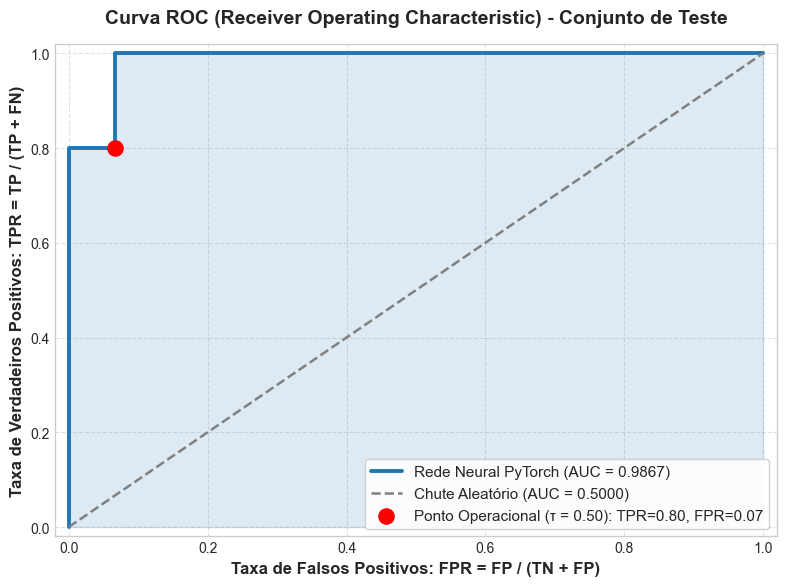

🌟 Área sob a Curva ROC (AUC-ROC): 0.9867 (98.67%)


In [12]:
# 1. Cálculo da Curva ROC e da Métrica AUC
fpr, tpr, limiares = roc_curve(y_test, y_test_probs)
auc_score = roc_auc_score(y_test, y_test_probs)

# 2. Identificar o ponto correspondente ao limiar padrão (tau = 0.5)
idx_limiar_padrao = np.argmin(np.abs(limiares - 0.5))
fpr_padrao = fpr[idx_limiar_padrao]
tpr_padrao = tpr[idx_limiar_padrao]

# 3. Plotagem da Curva ROC
fig, ax = plt.subplots(figsize=(8, 6))

# Linha da Curva ROC do modelo PyTorch
ax.plot(fpr, tpr, color='#1f77b4', linewidth=2.8, label=f'Rede Neural PyTorch (AUC = {auc_score:.4f})')

# Área preenchida sob a curva
ax.fill_between(fpr, tpr, alpha=0.15, color='#1f77b4')

# Linha diagonal de referência (Classificador Aleatório: AUC = 0.5)
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1.8, label='Chute Aleatório (AUC = 0.5000)')

# Destaque do ponto de operação para tau = 0.5
ax.scatter(fpr_padrao, tpr_padrao, color='red', s=120, zorder=5, 
           label=f'Ponto Operacional (τ = 0.50): TPR={tpr_padrao:.2f}, FPR={fpr_padrao:.2f}')

ax.set_title("Curva ROC (Receiver Operating Characteristic) - Conjunto de Teste", fontweight='bold', pad=15)
ax.set_xlabel("Taxa de Falsos Positivos: FPR = FP / (TN + FP)", fontweight='bold')
ax.set_ylabel("Taxa de Verdadeiros Positivos: TPR = TP / (TP + FN)", fontweight='bold')
ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.02])
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='lower right')
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"🌟 Área sob a Curva ROC (AUC-ROC): {auc_score:.4f} ({auc_score*100:.2f}%)")


## 11. Relatório de Classificação Consolidado e Conclusão

Para finalizar nossa análise, imprimimos o **Relatório de Classificação (*Classification Report*)**, que resume o desempenho para cada uma das classes individualmente e calcula as médias ponderadas e macro.


In [13]:
# Relatório detalhado por classe
relatorio = classification_report(
    y_test, y_test_pred, 
    target_names=['Versicolor (0)', 'Virginica (1)'],
    digits=4
)
print("📑 Relatório de Classificação Detalhado (Scikit-Learn):")
print(relatorio)


📑 Relatório de Classificação Detalhado (Scikit-Learn):
                precision    recall  f1-score   support

Versicolor (0)     0.8750    0.9333    0.9032        15
 Virginica (1)     0.9286    0.8667    0.8966        15

      accuracy                         0.9000        30
     macro avg     0.9018    0.9000    0.8999        30
  weighted avg     0.9018    0.9000    0.8999        30



---

## 🎓 Síntese da Aula e Exercícios Práticos Sugeridos

Hoje você construiu um fluxo completo de Inteligência Artificial moderna com **PyTorch**:
1. Explorou a geometria das **features** e visualizou os **pontos** das flores em 2D.
2. Projetou a **arquitetura de uma Rede Neural** (`nn.Module`) com camadas densas e funções de ativação $\text{ReLU}$ e $\text{Sigmoid}$.
3. Treinou o modelo através das 5 etapas do PyTorch e inspecionou as **curvas de aprendizado (Loss e Accuracy)**.
4. Mapeou a **fronteira de decisão contínua** separando as espécies no plano cartesiano.
5. Calculou as principais **figuras de mérito**: Matriz de Confusão, Acurácia, Precisão, Sensibilidade, F1-Score e Especificidade.
6. Inspecionou os **histogramas de saída da rede neural** para treino e teste, compreendendo o papel do limiar (*threshold*) e a separação das classes por setas direcionais.
7. Dominou a **Curva ROC** e a métrica **AUC**, entendendo como a variação do limiar governa a relação entre sensibilidade e falsos positivos.

---

### 🧪 Exercícios Práticos para Fixação:
1. **Exercício 1 (Arquitetura)**: Altere o número de neurônios da camada oculta de 16 para 4 e depois para 64. Como a suavidade da fronteira de decisão e a separação nos histogramas se comportam?
2. **Exercício 2 (Limiar de Decisão)**: Com base no histograma de saídas, mude o limiar $\tau$ de 0.50 para 0.20 e depois para 0.80. Observe como a linha vertical se desloca, alterando a Matriz de Confusão e o trade-off entre Precisão e Recall.
3. **Exercício 3 (Outras Espécies)**: Altere o filtro inicial para classificar *Setosa (0)* vs. *Versicolor (1)*. Como essa fronteira de decisão difere da fronteira entre *Versicolor* e *Virginica*?

*Bons estudos e continue explorando o universo do PyTorch!* 🚀✨
